# The NBA three-point revolution: what changed after Stephen Curry arrived?
**Question.** Did the league's three-point *percentage* rise after Stephen Curry entered the NBA (2009-10)? What changed instead?

**Data.** League-wide per-game totals by season and Curry's per-game stats, both from Basketball-Reference (see README for source and limits).
**Design.** Compare seasons *before* (1997-98 to 2008-09, same three-point line) with seasons *after* (2009-10 to 2025-26). This is a before/after comparison, not proof that Curry caused anything.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
league = pd.read_csv("data/league_3pt_by_season.csv")
curry = pd.read_csv("data/curry_3pt_by_season.csv")
league["year"] = league["season"].str[:4].astype(int)  # season start year
curry["year"] = curry["season"].str[:4].astype(int)
league.tail(3)

,season,3P,3PA,3P_pct,FG_pct,pace,games,year
44,2023-24,12.8,35.1,0.366,0.474,98.5,1230,2023
45,2024-25,13.5,37.6,0.360,0.467,98.8,1230,2024
46,2025-26,13.3,37.0,0.360,0.471,99.4,1230,2025


## 1. Define the windows
The NBA moved the three-point line in 1994-95 to 1996-97 and then moved it back. I start at 1997-98 so the line is the same in both windows. Curry's first season is 2009-10.

In [2]:
before = league[(league.year >= 1997) & (league.year <= 2008)]
after = league[league.year >= 2009]
print(len(before), "seasons before;", len(after), "seasons after")

def pooled_pct(df):
    # weight each season by total attempts (attempts per game x games)
    att = df["3PA"] * df["games"]
    return (df["3P_pct"] * att).sum() / att.sum()

summary = {
    "before_mean_3P_pct": round(before["3P_pct"].mean(), 4),
    "after_mean_3P_pct": round(after["3P_pct"].mean(), 4),
    "before_pooled_3P_pct": round(pooled_pct(before), 4),
    "after_pooled_3P_pct": round(pooled_pct(after), 4),
    "before_mean_3PA": round(before["3PA"].mean(), 1),
    "after_mean_3PA": round(after["3PA"].mean(), 1),
}
t_pct = stats.ttest_ind(after["3P_pct"], before["3P_pct"], equal_var=False)
t_att = stats.ttest_ind(after["3PA"], before["3PA"], equal_var=False)
summary["pct_diff_points"] = round((summary["after_mean_3P_pct"] - summary["before_mean_3P_pct"]) * 100, 2)
summary["pct_ttest_p"] = round(float(t_pct.pvalue), 3)
summary["3PA_ratio"] = round(summary["after_mean_3PA"] / summary["before_mean_3PA"], 2)
summary["3PA_ttest_p"] = float(f"{t_att.pvalue:.2e}")

# bootstrap CI on the difference in mean 3P%
rng = np.random.default_rng(680)
diffs = [rng.choice(after["3P_pct"], len(after)).mean() - rng.choice(before["3P_pct"], len(before)).mean() for _ in range(10000)]
summary["pct_diff_ci95_points"] = [round(float(np.percentile(diffs, q)) * 100, 2) for q in (2.5, 97.5)]
summary

12 seasons before; 17 seasons after


{'before_mean_3P_pct': np.float64(0.3536),
 'after_mean_3P_pct': np.float64(0.358),
 'before_pooled_3P_pct': np.float64(0.3548),
 'after_pooled_3P_pct': np.float64(0.3586),
 'before_mean_3PA': np.float64(15.2),
 'after_mean_3PA': np.float64(28.1),
 'pct_diff_points': np.float64(0.44),
 'pct_ttest_p': 0.093,
 '3PA_ratio': np.float64(1.85),
 '3PA_ttest_p': 1.27e-06,
 'pct_diff_ci95_points': [-0.02, 0.9]}

**Reading this.** The average league 3P% is about 0.4 percentage points higher after 2009 (35.4% to 35.8%). That is small, and the 95% interval runs from about 0 to 0.9 points, so it is weak evidence of any rise. Attempts nearly doubled (15 to 28 per game).

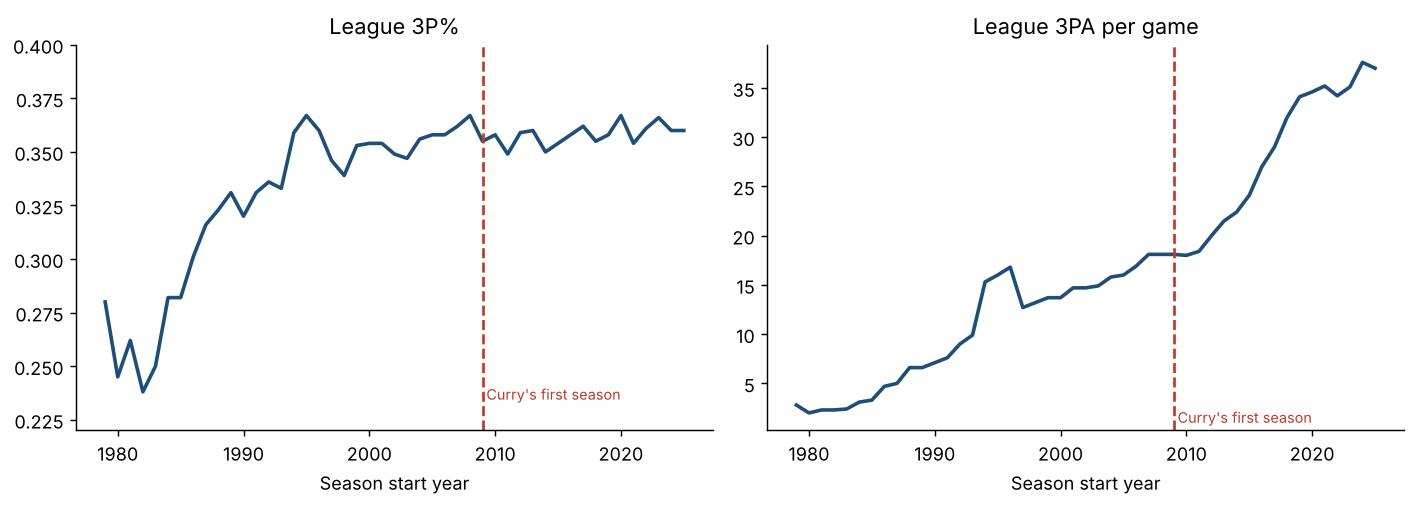

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, col, label in zip(ax, ["3P_pct", "3PA"], ["League 3P%", "League 3PA per game"]):
    a.plot(league.year, league[col], color="#1f4e79", lw=2)
    a.axvline(2009, color="#c0392b", ls="--")
    a.text(2009.3, a.get_ylim()[0] + 0.02 * (a.get_ylim()[1] - a.get_ylim()[0]), "Curry's first season", color="#c0392b", fontsize=8)
    a.set_title(label)
    a.set_xlabel("Season start year")
ax[0].set_ylim(0.22, 0.40)
plt.tight_layout()
plt.savefig("figures/fig1_league_pct_vs_attempts.png")
plt.show()

## 2. Was there a change in trend at 2009? (segmented regression)
I fit a line through each series with a level shift and a slope change at 2009 (a simple interrupted time series). With only ~28 seasons this is a rough tool, so I treat it as descriptive.

In [4]:
import statsmodels.formula.api as smf
d = league[league.year >= 1997].copy()
d["t"] = d.year - 1997
d["post"] = (d.year >= 2009).astype(int)
d["t_post"] = d.post * (d.year - 2009)
results = {}
for col in ["3P_pct", "3PA"]:
    m = smf.ols(f"Q('{col}') ~ t + post + t_post", data=d).fit(cov_type="HC3")
    results[col] = {
        "pre_slope_per_year": round(float(m.params["t"]), 4),
        "level_shift_at_2009": round(float(m.params["post"]), 4),
        "slope_change_after_2009": round(float(m.params["t_post"]), 4),
        "p_slope_change": round(float(m.pvalues["t_post"]), 4),
    }
results

{'3P_pct': {'pre_slope_per_year': 0.0017,
  'level_shift_at_2009': -0.0108,
  'slope_change_after_2009': -0.0013,
  'p_slope_change': 0.0068},
 '3PA': {'pre_slope_per_year': 0.4927,
  'level_shift_at_2009': -1.5694,
  'slope_change_after_2009': 0.9191,
  'p_slope_change': 0.0}}

**Reading this.** For attempts, the yearly growth rate nearly triples after 2009 (about +0.5 to +1.4 per game per year) and the change is statistically clear. For percentage, the slope *flattens*: it was creeping up about 0.17 points a year before 2009 and stops climbing after. So the percentage did not take off, even as volume did.

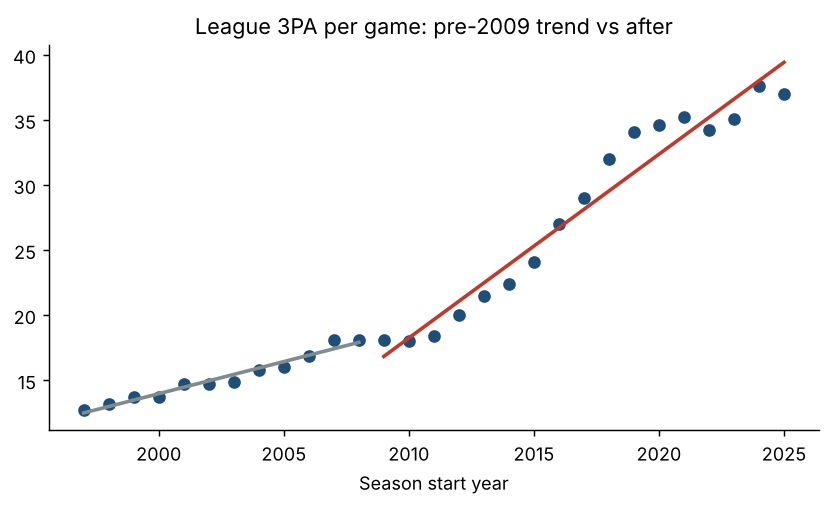

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(d.year, d["3PA"], color="#1f4e79")
for seg, c in [(d[d.post == 0], "#7f8c8d"), (d[d.post == 1], "#c0392b")]:
    p = np.polyfit(seg.year, seg["3PA"], 1)
    ax.plot(seg.year, np.polyval(p, seg.year), color=c, lw=2)
ax.set_title("League 3PA per game: pre-2009 trend vs after")
ax.set_xlabel("Season start year")
plt.tight_layout()
plt.savefig("figures/fig2_attempts_trend_break.png")
plt.show()

## 3. Curry versus the league
Curry shot far above the league average every full season. The gap is the story about *Curry*; the flat league percentage is the story about *the league*.

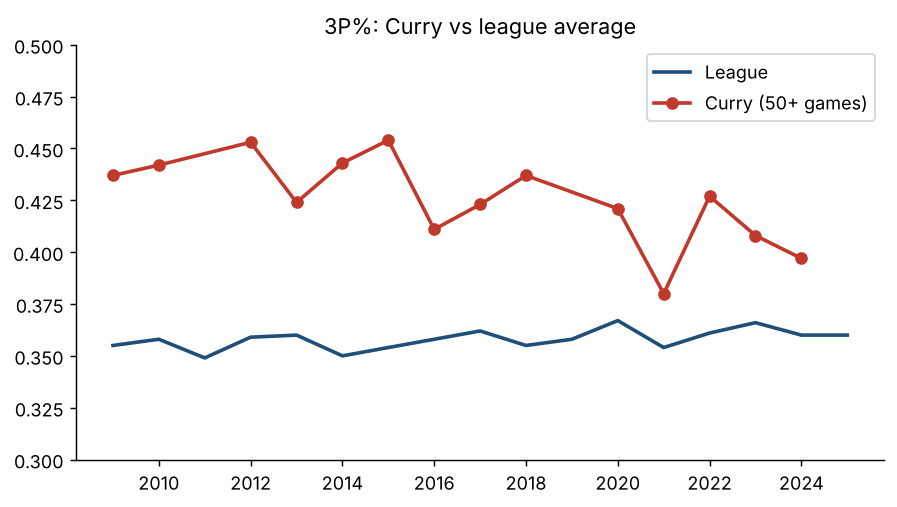

,season,3P_pct_curry,3P_pct_league,gap_points
0,2009-10,0.437,0.355,8.2
1,2010-11,0.442,0.358,8.4
3,2012-13,0.453,0.359,9.4
4,2013-14,0.424,0.360,6.4
5,2014-15,0.443,0.350,9.3
6,2015-16,0.454,0.354,10.0
7,2016-17,0.411,0.358,5.3
8,2017-18,0.423,0.362,6.1
9,2018-19,0.437,0.355,8.2
11,2020-21,0.421,0.367,5.4


In [6]:
m = curry.merge(league[["season", "3P_pct", "3PA"]], on="season", suffixes=("_curry", "_league"))
m = m[m.games >= 50]  # drop injury-shortened seasons (2011-12, 2019-20) for the comparison
m["gap_points"] = (m["3P_pct_curry"] - m["3P_pct_league"]) * 100
summary["curry_career_3P_pct_seasons50plus_games"] = round(float((m["3P_pct_curry"] * m["3PA_curry"] * m["games"]).sum() / (m["3PA_curry"] * m["games"]).sum()), 3)
summary["curry_avg_gap_over_league_points"] = round(float(m["gap_points"].mean()), 1)
summary["curry_3PA_first_vs_peak"] = [float(curry["3PA"].iloc[0]), float(curry["3PA"].max())]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(league[league.year >= 2009].year, league[league.year >= 2009]["3P_pct"], label="League", color="#1f4e79", lw=2)
ax.plot(m.year, m["3P_pct_curry"], label="Curry (50+ games)", color="#c0392b", lw=2, marker="o")
ax.set_ylim(0.30, 0.50)
ax.set_title("3P%: Curry vs league average")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig3_curry_vs_league.png")
plt.show()
m[["season", "3P_pct_curry", "3P_pct_league", "gap_points"]].round(3)

## 4. Takeaways and limits
* League 3P% rose only slightly (about +0.4 points on average, not clearly different from zero) and its upward trend flattened after 2009. It sat near 35-36% throughout.
* League 3P *attempts* rose steeply and grew faster after 2009.
* Curry hit about 42% on large volume, so he is a clear outlier, but a before/after comparison cannot show he *caused* the league-wide shift. Analytics, rule changes (2004 hand-checking rules), coaching, and player development all moved in the same period.
* Data are season averages from a secondary source, rounded to one decimal for per-game counts. They are fine for league trends, not for fine-grained claims.

In [7]:
out = {"summary": summary, "segmented_regression": results}
with open("results.json", "w") as f:
    json.dump(out, f, indent=2)
print(json.dumps(out, indent=2))

{
  "summary": {
    "before_mean_3P_pct": 0.3536,
    "after_mean_3P_pct": 0.358,
    "before_pooled_3P_pct": 0.3548,
    "after_pooled_3P_pct": 0.3586,
    "before_mean_3PA": 15.2,
    "after_mean_3PA": 28.1,
    "pct_diff_points": 0.44,
    "pct_ttest_p": 0.093,
    "3PA_ratio": 1.85,
    "3PA_ttest_p": 1.27e-06,
    "pct_diff_ci95_points": [
      -0.02,
      0.9
    ],
    "curry_career_3P_pct_seasons50plus_games": 0.424,
    "curry_avg_gap_over_league_points": 6.7,
    "curry_3PA_first_vs_peak": [
      4.8,
      12.7
    ]
  },
  "segmented_regression": {
    "3P_pct": {
      "pre_slope_per_year": 0.0017,
      "level_shift_at_2009": -0.0108,
      "slope_change_after_2009": -0.0013,
      "p_slope_change": 0.0068
    },
    "3PA": {
      "pre_slope_per_year": 0.4927,
      "level_shift_at_2009": -1.5694,
      "slope_change_after_2009": 0.9191,
      "p_slope_change": 0.0
    }
  }
}
